# Predicting late deliveries: model training

**Goal.** Flag orders that will be delivered late, so they can be handled early.


**Data split (by time).** Train, then validation, then test. Test is reported once in this notebook, after all choices were fixed. Earlier iterations also scored it, so test numbers may be slightly optimistic.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             fbeta_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

pd.set_option("display.width", 200)

In [2]:
RANDOM_STATE = 42
TARGET = "late_delivery_risk"
DATE = "order_date_dateorders"
FOLDER = "../data/processed/"

# Business assumption, set on validation: at least 70% of flagged orders should really be late.
PRECISION_FLOOR = 0.70

## 2. Load data

In [3]:
train = pd.read_csv(FOLDER + "train_features.csv", parse_dates=[DATE]).sort_values(DATE).reset_index(drop=True)
val = pd.read_csv(FOLDER + "val_features.csv", parse_dates=[DATE]).sort_values(DATE).reset_index(drop=True)
print(f"Train: {len(train):,} rows  ({train[DATE].min():%Y-%m-%d} to {train[DATE].max():%Y-%m-%d})")
print(f"Valid: {len(val):,} rows  ({val[DATE].min():%Y-%m-%d} to {val[DATE].max():%Y-%m-%d})")

Train: 44,028 rows  (2015-01-01 to 2017-03-16)
Valid: 9,434 rows  (2017-03-16 to 2017-09-05)


In [4]:
# 7 base features. Order-size columns are left out on purpose: average order size
# shifts a lot in the test period, so a model relying on it would not carry over.
feature_cols = ["shipping_mode", "same_day_after_cutoff", "order_hour", "order_day_of_week",
                "order_month", "is_weekend", "order_is_holiday_season"]

X_train, y_train = train[feature_cols], train[TARGET]
X_val, y_val = val[feature_cols], val[TARGET]

In [5]:
late_share = pd.DataFrame({"late_share": [y_train.mean(), y_val.mean()]}, index=["train", "validation"])
display(late_share.round(3))

,late_share
train,0.573
validation,0.570


## 3. Helper functions

Column lists cover every column used anywhere in this notebook (the pipeline keeps only the ones it is given).

In [6]:
TEXT_COLS = ["shipping_mode", "type", "customer_segment", "market", "order_region",
             "mode_hour", "mode_weekday", "mode_region", "same_day_period"]
NUMERIC_COLS = ["same_day_after_cutoff", "order_hour", "order_day_of_week", "order_month",
                "is_weekend", "order_is_holiday_season",
                "order_country_freq", "order_state_freq", "order_city_freq"]

def make_pipeline(model, columns, scale=False):
    text = [c for c in columns if c in TEXT_COLS]
    numeric = [c for c in columns if c in NUMERIC_COLS]
    prep = ColumnTransformer(
        [("text", OneHotEncoder(handle_unknown="ignore"), text),
         ("numeric", StandardScaler() if scale else "passthrough", numeric)],
        remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("preprocess", prep), ("model", model)])

In [7]:
def score(y, probability, cutoff=0.5):
    y = np.asarray(y); probability = np.asarray(probability)
    pred = (probability >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"cutoff": cutoff,
            "recall": recall_score(y, pred, zero_division=0),
            "precision": precision_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "accuracy": accuracy_score(y, pred),
            "AUC": roc_auc_score(y, probability),
            "PR-AUC": average_precision_score(y, probability),
            "late_missed": int(fn), "false_alarms": int(fp),
            "share_flagged": float(pred.mean())}

In [8]:
CUTOFFS = np.round(np.arange(0.05, 0.9501, 0.01), 2)

def cutoff_table(y, p):
    y = np.asarray(y); p = np.asarray(p)
    rows = []
    for c in CUTOFFS:
        flag = p >= c
        tp = int((flag & (y == 1)).sum()); fp = int((flag & (y == 0)).sum())
        fn = int((~flag & (y == 1)).sum()); tn = int((~flag & (y == 0)).sum())
        rows.append({"cutoff": c, "recall": tp / (tp + fn),
                     "precision": tp / (tp + fp) if (tp + fp) else np.nan,
                     "accuracy": (tp + tn) / len(y), "share_flagged": flag.mean(),
                     "tp": tp, "fp": fp, "fn": fn})
    return pd.DataFrame(rows).set_index("cutoff")

def pick_cutoff(table, floor):
    # highest recall that still meets the precision floor; on ties, the highest cutoff (fewer false alarms)
    ok = table[table["precision"] >= floor]
    if ok.empty:
        return None
    return ok[ok["recall"] == ok["recall"].max()].index.max()

## 4. Baseline

Logistic regression on the 7 features, no tuning, is the baseline. Every other model has to beat it.

In [9]:
baseline_lr = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), feature_cols, scale=True)
baseline_lr.fit(X_train, y_train)
p_lr_val = baseline_lr.predict_proba(X_val)[:, 1]

In [10]:
t_lr = cutoff_table(y_val, p_lr_val)
c_lr = pick_cutoff(t_lr, PRECISION_FLOOR)

baseline = pd.DataFrame({
    "logistic regression (baseline)": {"PR-AUC": average_precision_score(y_val, p_lr_val),
                                       "AUC": roc_auc_score(y_val, p_lr_val),
                                       "recall": t_lr.loc[c_lr, "recall"] if c_lr is not None else np.nan,
                                       "precision": t_lr.loc[c_lr, "precision"] if c_lr is not None else np.nan},
}).T
print(f"Validation, precision floor {PRECISION_FLOOR:.2f}, logistic regression cutoff at the floor: {c_lr}")
display(baseline.round(3))
print("LR needs a very high cutoff (0.79) to reach the 70% floor, so its recall here is low. Compare models at equal precision (table in section 7).")

Validation, precision floor 0.70, logistic regression cutoff at the floor: 0.79


,PR-AUC,AUC,recall,precision
logistic regression (baseline),0.855,0.776,0.59,0.893


LR needs a very high cutoff (0.79) to reach the 70% floor, so its recall here is low. Compare models at equal precision (table in section 7).


## 5. Candidate models (default settings)

Five models on the same 7 features. Logistic regression is the simple reference.

In [11]:
models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), feature_cols, scale=True),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=-1), feature_cols),
    "LightGBM": make_pipeline(LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=RANDOM_STATE, verbosity=-1), feature_cols),
    "XGBoost": make_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1), feature_cols),
    "CatBoost": make_pipeline(CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, random_seed=RANDOM_STATE, verbose=0), feature_cols),
}
for name, model in models.items():
    model.fit(X_train, y_train)
print("Fitted:", list(models))

Fitted: ['Logistic Regression', 'Random Forest', 'LightGBM', 'XGBoost', 'CatBoost']


In [12]:
def split_metrics(models_dict, cutoff=0.5):
    rows = []
    for name, m in models_dict.items():
        for split, X, y in [("train", X_train, y_train), ("validation", X_val, y_val)]:
            p = m.predict_proba(X)[:, 1]
            pred = p >= cutoff
            rows.append({"model": name, "split": split,
                         "accuracy": accuracy_score(y, pred),
                         "recall": recall_score(y, pred, zero_division=0),
                         "precision": precision_score(y, pred, zero_division=0),
                         "AUC": roc_auc_score(y, p),
                         "PR-AUC": average_precision_score(y, p)})
    metrics = ["accuracy", "recall", "precision", "AUC", "PR-AUC"]
    table = pd.DataFrame(rows).pivot(index="model", columns="split", values=metrics)
    table = table[[(m, s) for m in metrics for s in ["train", "validation"]]]
    return table.loc[list(models_dict)]

print("Accuracy, recall and precision use a cutoff of 0.50. AUC and PR-AUC do not depend on a cutoff.")
display(split_metrics(models).round(3))

Accuracy, recall and precision use a cutoff of 0.50. AUC and PR-AUC do not depend on a cutoff.


accuracy            recall            precision               AUC            PR-AUC           
split                  train validation  train validation     train validation  train validation  train validation
model                                                                                                             
Logistic Regression    0.722      0.726  0.582      0.590     0.896      0.893  0.776      0.776  0.856      0.855
Random Forest          0.726      0.725  0.598      0.597     0.888      0.884  0.830      0.789  0.886      0.862
LightGBM               0.727      0.725  0.597      0.597     0.889      0.884  0.829      0.794  0.886      0.864
XGBoost                0.725      0.725  0.591      0.590     0.892      0.891  0.810      0.779  0.876      0.857
CatBoost               0.722      0.726  0.584      0.590     0.895      0.893  0.797      0.778  0.869      0.856

## 6. Tuning with grid search

`GridSearchCV` over LightGBM and XGBoost, scored by PR-AUC with `TimeSeriesSplit` (each fold trains on the past and validates on the next block, so no future data leaks backwards). Tuning uses only the training set.

Why grid search: the space is small (192 combinations per model), so I can try all of them and the result is fully reproducible.

In [13]:
lgbm_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__n_estimators": [200, 400],
    "model__num_leaves": [15, 31, 63],
    "model__min_child_samples": [20, 50],
    "model__reg_lambda": [0, 2],
    "model__class_weight": [None, {0: 1, 1: 1.5}, {0: 1, 1: 2}, {0: 1, 1: 3}],
}
xgb_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 5, 7],
    "model__min_child_weight": [1, 5],
    "model__reg_lambda": [1, 3],
    "model__scale_pos_weight": [1, 1.5, 2, 3],
}
grids = {
    "LightGBM tuned": (make_pipeline(LGBMClassifier(random_state=RANDOM_STATE, verbosity=-1, n_jobs=1), feature_cols), lgbm_grid),
    "XGBoost tuned": (make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1), feature_cols), xgb_grid),
}

In [14]:
import time
searches = {}
for name, (pipe, grid) in grids.items():
    start = time.time()
    search = GridSearchCV(pipe, grid, scoring="average_precision", cv=TimeSeriesSplit(n_splits=4),
                          n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    models[name] = search.best_estimator_
    print(f"{name}: best CV PR-AUC {search.best_score_:.4f}  ({time.time() - start:.0f}s)")

LightGBM tuned: best CV PR-AUC 0.8607  (178s)
XGBoost tuned: best CV PR-AUC 0.8598  (155s)


In [15]:
best_params = pd.DataFrame({n: {k.replace("model__", ""): str(v) for k, v in s.best_params_.items()}
                            for n, s in searches.items()}).fillna("-")
display(best_params)

,LightGBM tuned,XGBoost tuned
class_weight,None,-
learning_rate,0.05,0.05
min_child_samples,20,-
n_estimators,400,400
num_leaves,63,-
reg_lambda,0,3
max_depth,-,7
min_child_weight,-,1
scale_pos_weight,-,1.5


## 7. Did tuning help?

Rule set before looking: keep the tuned model only if validation PR-AUC improves by at least 0.002.
PR-AUC is used for this decision because it is stable; recall at a fixed precision floor can jump a lot between neighbouring cutoffs.

In [16]:
def summarize(models_dict):
    rows = {}
    for name, m in models_dict.items():
        p_v = m.predict_proba(X_val)[:, 1]
        p_t = m.predict_proba(X_train)[:, 1]
        t = cutoff_table(y_val, p_v)
        cut = pick_cutoff(t, PRECISION_FLOOR)
        rows[name] = {"PR-AUC (val)": average_precision_score(y_val, p_v),
                      "AUC (val)": roc_auc_score(y_val, p_v),
                      "AUC gap (train - val)": roc_auc_score(y_train, p_t) - roc_auc_score(y_val, p_v),
                      "cutoff at floor": cut if cut is not None else np.nan,
                      "recall at floor": t.loc[cut, "recall"] if cut is not None else np.nan,
                      "precision at floor": t.loc[cut, "precision"] if cut is not None else np.nan}
    out = pd.DataFrame(rows).T
    out.index.name = "model"
    return out

all_summary = summarize(models)
display(all_summary.sort_values("PR-AUC (val)", ascending=False).round(3))

,PR-AUC (val),AUC (val),AUC gap (train - val),cutoff at floor,recall at floor,precision at floor
model,,,,,,
LightGBM tuned,0.868,0.803,0.043,0.40,0.815,0.704
LightGBM,0.864,0.794,0.035,0.40,0.791,0.706
Random Forest,0.862,0.789,0.041,0.41,0.773,0.709
XGBoost tuned,0.860,0.784,0.040,0.51,0.738,0.728
XGBoost,0.857,0.779,0.031,0.41,0.712,0.740
CatBoost,0.856,0.778,0.019,0.41,0.672,0.776
Logistic Regression,0.855,0.776,-0.001,0.79,0.590,0.893


In [17]:
verdicts = []
for tuned, base in [("LightGBM tuned", "LightGBM"), ("XGBoost tuned", "XGBoost")]:
    d_pr = all_summary.loc[tuned, "PR-AUC (val)"] - all_summary.loc[base, "PR-AUC (val)"]
    d_rec = all_summary.loc[tuned, "recall at floor"] - all_summary.loc[base, "recall at floor"]
    verdicts.append({"tuned vs untuned": f"{tuned} vs {base}", "PR-AUC change": d_pr,
                     "recall-at-floor change": d_rec, "keep tuned": d_pr >= 0.002})
display(pd.DataFrame(verdicts).set_index("tuned vs untuned").round(4))

,PR-AUC change,recall-at-floor change,keep tuned
tuned vs untuned,,,
LightGBM tuned vs LightGBM,0.0040,0.0238,True
XGBoost tuned vs XGBoost,0.0022,0.0260,True


### Do the models beat the logistic regression baseline?

Same rule as above: a model beats the baseline only if its validation PR-AUC is at least 0.002 higher. Recall at the floor is shown as well, because that is where the boosted models usually pull ahead.

In [18]:
lr_row = all_summary.loc["Logistic Regression"]
vs_lr = pd.DataFrame({
    "PR-AUC gain vs LR": all_summary["PR-AUC (val)"] - lr_row["PR-AUC (val)"],
    "AUC gain vs LR": all_summary["AUC (val)"] - lr_row["AUC (val)"],
    "recall-at-floor gain vs LR": all_summary["recall at floor"] - lr_row["recall at floor"],
}).drop("Logistic Regression")
vs_lr["beats LR"] = vs_lr["PR-AUC gain vs LR"] >= 0.002
display(vs_lr.sort_values("PR-AUC gain vs LR", ascending=False).round(3))

,PR-AUC gain vs LR,AUC gain vs LR,recall-at-floor gain vs LR,beats LR
model,,,,
LightGBM tuned,0.013,0.027,0.226,True
LightGBM,0.009,0.018,0.202,True
Random Forest,0.007,0.013,0.184,True
XGBoost tuned,0.005,0.008,0.148,True
XGBoost,0.002,0.003,0.122,True
CatBoost,0.002,0.002,0.082,False


Logistic Regression can only reach the 0.70 floor at a very high cutoff, so the recall gap there is inflated. The fair comparison is recall at the same precision.

In [19]:
rows = {}
for name, m in models.items():
    p = m.predict_proba(X_val)[:, 1]
    t = cutoff_table(y_val, p)
    row = {"PR-AUC": average_precision_score(y_val, p)}
    for f in [0.60, 0.65, 0.70, 0.75]:
        c = pick_cutoff(t, f)
        row[f"recall @ P>={f:.2f}"] = t.loc[c, "recall"] if c is not None else np.nan
    rows[name] = row
display(pd.DataFrame(rows).T.sort_values("recall @ P>=0.65", ascending=False).round(3))

,PR-AUC,recall @ P>=0.60,recall @ P>=0.65,recall @ P>=0.70,recall @ P>=0.75
LightGBM tuned,0.868,0.975,0.888,0.815,0.734
Random Forest,0.862,0.962,0.841,0.773,0.695
XGBoost tuned,0.860,0.953,0.827,0.738,0.705
LightGBM,0.864,0.953,0.791,0.791,0.715
Logistic Regression,0.855,0.789,0.789,0.590,0.590
CatBoost,0.856,0.899,0.781,0.672,0.672
XGBoost,0.857,0.950,0.779,0.712,0.670


### Why only 7 features?

Same tuned LightGBM settings, adding one group of extra columns at a time (validation).

In [20]:
best = {k.replace("model__", ""): v for k, v in searches["LightGBM tuned"].best_params_.items()}
fgroups = {
    "7 base features": [],
    "+ place": ["order_country_freq", "order_state_freq", "order_city_freq"],
    "+ type and customer": ["type", "customer_segment"],
    "+ market and region": ["market", "order_region"],
    "+ combined ideas": ["mode_hour", "mode_weekday", "mode_region", "same_day_period"],
}
rows = {}
for name, extra in fgroups.items():
    cols = feature_cols + extra
    m = make_pipeline(LGBMClassifier(**best, random_state=RANDOM_STATE, verbosity=-1), cols).fit(train[cols], y_train)
    p_v, p_t = m.predict_proba(val[cols])[:, 1], m.predict_proba(train[cols])[:, 1]
    t = cutoff_table(y_val, p_v); c = pick_cutoff(t, PRECISION_FLOOR)
    rows[name] = {"n features": len(cols), "PR-AUC": average_precision_score(y_val, p_v),
                  "AUC gap (train - val)": roc_auc_score(y_train, p_t) - roc_auc_score(y_val, p_v),
                  "recall at floor": t.loc[c, "recall"] if c is not None else np.nan}
display(pd.DataFrame(rows).T.round(3))

,n features,PR-AUC,AUC gap (train - val),recall at floor
7 base features,7.0,0.868,0.043,0.815
+ place,10.0,0.863,0.103,0.783
+ type and customer,9.0,0.857,0.088,0.745
+ market and region,9.0,0.859,0.072,0.749
+ combined ideas,11.0,0.860,0.070,0.756


None of the extra groups improved recall at the same precision, and they widened the train-validation gap.

## 8. Choose the model and the cutoff

Model: highest validation PR-AUC. Cutoff: the one that gives the highest recall while precision stays at or above the floor.

In [21]:
CHOSEN_NAME = all_summary["PR-AUC (val)"].idxmax()
p_val = models[CHOSEN_NAME].predict_proba(X_val)[:, 1]
val_table = cutoff_table(y_val, p_val)
CHOSEN_CUTOFF = pick_cutoff(val_table, PRECISION_FLOOR)

print("Chosen model :", CHOSEN_NAME)
print("Chosen cutoff:", CHOSEN_CUTOFF, f"(highest recall with precision >= {PRECISION_FLOOR:.2f} on validation)")

Chosen model : LightGBM tuned
Chosen cutoff: 0.4 (highest recall with precision >= 0.70 on validation)


In [22]:
display(val_table.loc[[CHOSEN_CUTOFF], ["recall", "precision", "accuracy", "share_flagged", "tp", "fp", "fn"]].round(3))

,recall,precision,accuracy,share_flagged,tp,fp,fn
cutoff,,,,,,,
0.4,0.815,0.704,0.7,0.66,4385,1840,994


In [23]:
v = val_table[(val_table.index <= 0.50) & (val_table.index >= 0.34)].sort_index(ascending=False)[["recall", "precision", "accuracy"]].copy()
v["recall change (pts)"] = v["recall"].diff() * 100
v["accuracy change (pts)"] = v["accuracy"].diff() * 100
display(v.round(3))

,recall,precision,accuracy,recall change (pts),accuracy change (pts)
cutoff,,,,,
0.50,0.612,0.870,0.726,NaN,NaN
0.49,0.618,0.862,0.726,0.613,-0.042
0.48,0.626,0.855,0.726,0.781,0.021
0.47,0.637,0.844,0.726,1.097,-0.032
0.46,0.651,0.831,0.726,1.469,-0.021
0.45,0.666,0.818,0.725,1.431,-0.053
0.44,0.679,0.808,0.725,1.357,0.000
0.43,0.701,0.787,0.721,2.194,-0.382
0.42,0.734,0.763,0.718,3.309,-0.318


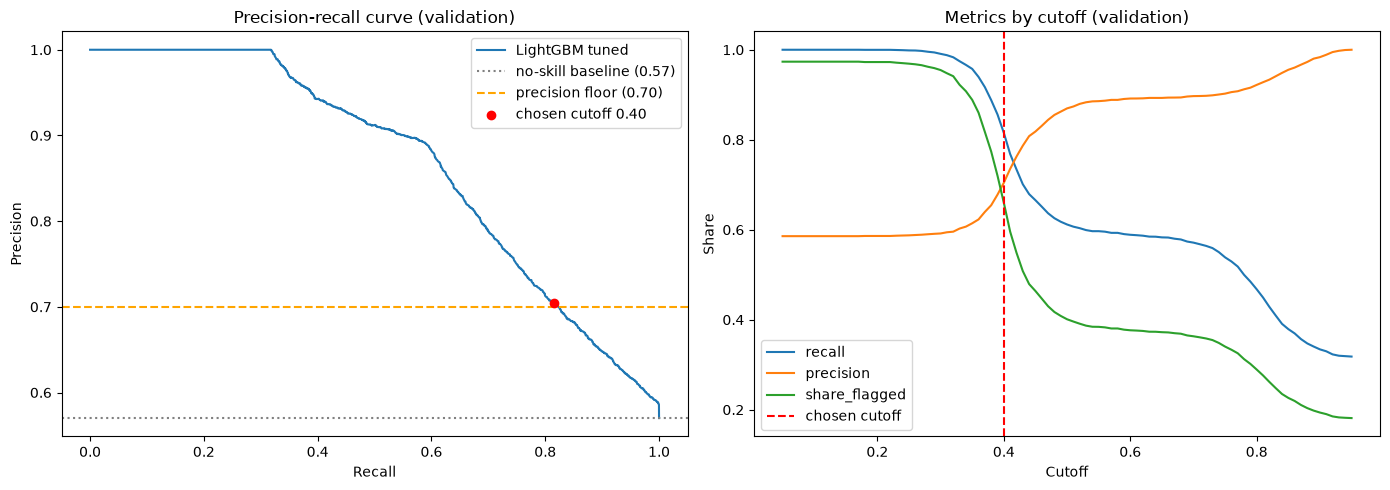

In [24]:
prec, rec, _ = precision_recall_curve(y_val, p_val)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(rec, prec, label=CHOSEN_NAME)
ax[0].axhline(y_val.mean(), color="grey", linestyle=":", label=f"no-skill baseline ({y_val.mean():.2f})")
ax[0].axhline(PRECISION_FLOOR, color="orange", linestyle="--", label=f"precision floor ({PRECISION_FLOOR:.2f})")
ax[0].scatter(val_table.loc[CHOSEN_CUTOFF, "recall"], val_table.loc[CHOSEN_CUTOFF, "precision"],
              color="red", zorder=5, label=f"chosen cutoff {CHOSEN_CUTOFF:.2f}")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision-recall curve (validation)"); ax[0].legend()

for col in ["recall", "precision", "share_flagged"]:
    ax[1].plot(val_table.index, val_table[col], label=col)
ax[1].axvline(CHOSEN_CUTOFF, color="red", linestyle="--", label="chosen cutoff")
ax[1].set_xlabel("Cutoff"); ax[1].set_ylabel("Share")
ax[1].set_title("Metrics by cutoff (validation)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Final test evaluation (reported once)

Everything above is fixed: features, models, settings and the cutoff. Reported once in this notebook, after all choices were fixed. Earlier iterations also scored it, so test numbers may be slightly optimistic. Every model is scored at the same two cutoffs: **0.50** (the standard default) and the **cutoff chosen on validation**. No changes after this point.

In [25]:
test = pd.read_csv(FOLDER + "test_features.csv", parse_dates=[DATE]).sort_values(DATE, kind="stable").reset_index(drop=True)
X_test, y_test = test[feature_cols], test[TARGET]
print(f"Test: {len(test):,} rows  ({test[DATE].min():%Y-%m-%d} to {test[DATE].max():%Y-%m-%d}); late share {y_test.mean():.1%}")

Test: 9,435 rows  (2017-09-05 to 2018-01-31); late share 57.5%


In [26]:
print("train max / val min :", train[DATE].max(), "/", val[DATE].min())
print("val max / test min  :", val[DATE].max(), "/", test[DATE].min())
if "order_id" in train.columns:
    for a, b, n in [(train, val, "train-val"), (val, test, "val-test"), (train, test, "train-test")]:
        print(f"shared order_id {n}:", len(set(a["order_id"]) & set(b["order_id"])))

train max / val min : 2017-03-16 15:09:00 / 2017-03-16 15:51:00
val max / test min  : 2017-09-05 13:20:00 / 2017-09-05 13:41:00
shared order_id train-val: 0
shared order_id val-test: 0
shared order_id train-test: 0


In [27]:
CUTOFFS_TO_REPORT = [0.50, CHOSEN_CUTOFF]
cols = ["recall", "precision", "F2", "accuracy", "AUC", "PR-AUC", "late_missed", "false_alarms", "share_flagged"]

tables = {}
for cutoff in CUTOFFS_TO_REPORT:
    rows = []
    for name, m in models.items():
        p = m.predict_proba(X_test)[:, 1]
        rows.append({"model": name, **score(y_test, p, cutoff)})
    tables[cutoff] = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC", ascending=False)
    print(f"Test results at cutoff {cutoff:.2f}")
    display(tables[cutoff][cols].round(3))


final_table = tables[CUTOFFS_TO_REPORT[-1]]
p_test = models[CHOSEN_NAME].predict_proba(X_test)[:, 1]

Test results at cutoff 0.50


,recall,precision,F2,accuracy,AUC,PR-AUC,late_missed,false_alarms,share_flagged
model,,,,,,,,,
LightGBM tuned,0.629,0.859,0.664,0.727,0.808,0.874,2016,561,0.421
LightGBM,0.601,0.883,0.642,0.724,0.800,0.869,2168,434,0.392
XGBoost tuned,0.798,0.693,0.775,0.680,0.793,0.866,1095,1920,0.663
XGBoost,0.598,0.887,0.640,0.725,0.789,0.864,2181,413,0.388
Random Forest,0.598,0.882,0.639,0.723,0.788,0.864,2185,433,0.390
CatBoost,0.591,0.895,0.634,0.724,0.782,0.861,2223,377,0.380
Logistic Regression,0.587,0.897,0.631,0.724,0.775,0.858,2242,364,0.376


Test results at cutoff 0.40


,recall,precision,F2,accuracy,AUC,PR-AUC,late_missed,false_alarms,share_flagged
model,,,,,,,,,
LightGBM tuned,0.825,0.706,0.798,0.702,0.808,0.874,951,1862,0.672
LightGBM,0.803,0.705,0.781,0.694,0.800,0.869,1070,1821,0.655
XGBoost tuned,0.987,0.599,0.874,0.613,0.793,0.866,69,3581,0.948
XGBoost,0.808,0.687,0.781,0.678,0.789,0.864,1040,1999,0.677
Random Forest,0.800,0.692,0.776,0.680,0.788,0.864,1085,1934,0.665
CatBoost,0.782,0.689,0.762,0.672,0.782,0.861,1183,1913,0.653
Logistic Regression,0.806,0.672,0.775,0.661,0.775,0.858,1055,2139,0.690


Cutoffs are not comparable across models. XGBoost tuned used a class weight, so its scores run higher and 0.40 is not its cutoff. Only the chosen model's row is the result.

In [28]:
cm = confusion_matrix(y_test, p_test >= CHOSEN_CUTOFF, labels=[0, 1])
display(pd.DataFrame(cm, index=["actual on-time", "actual late"], columns=["predicted on-time", "predicted late"]))

,predicted on-time,predicted late
actual on-time,2144,1862
actual late,951,4478


In [29]:
d = pd.DataFrame({"mode": test["shipping_mode"].values, "late": y_test.values, "flag": p_test >= CHOSEN_CUTOFF})
rows = {}
for mode, g in d.groupby("mode"):
    late = g[g.late == 1]
    rows[mode] = {"orders": len(g), "late share": g.late.mean(),
                  "recall": late.flag.mean() if len(late) else np.nan,
                  "late missed": int((~late.flag).sum()),
                  "false alarms": int(((g.late == 0) & g.flag).sum())}
display(pd.DataFrame(rows).T.round(3))

,orders,late share,recall,late missed,false alarms
First Class,1438.0,1.000,1.000,0.0,0.0
Same Day,508.0,0.531,1.000,0.0,0.0
Second Class,1843.0,0.802,1.000,0.0,364.0
Standard Class,5646.0,0.397,0.576,951.0,1498.0


## 10. What drives the model?

In [30]:
chosen = models[CHOSEN_NAME]
names = chosen.named_steps["preprocess"].get_feature_names_out()
est = chosen.named_steps["model"]
raw = est.booster_.feature_importance(importance_type="gain") if hasattr(est, "booster_") else est.feature_importances_

importance = pd.Series(raw, index=names)
importance.index = ["shipping_mode" if n.startswith("shipping_mode_") else n for n in importance.index]
importance = importance.groupby(level=0).sum()
importance = (importance / importance.sum()).sort_values(ascending=False)
display(importance.to_frame("importance share").round(3))

,importance share
shipping_mode,0.716
same_day_after_cutoff,0.150
order_hour,0.049
order_month,0.045
order_day_of_week,0.040
is_weekend,0.001
order_is_holiday_season,0.001


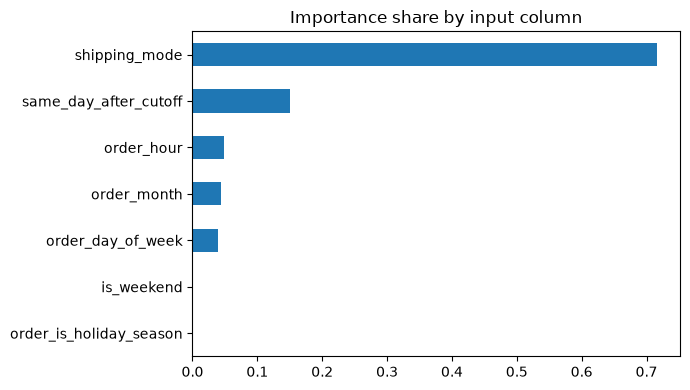

In [31]:
importance.sort_values().plot.barh(figsize=(7, 4), title="Importance share by input column")
plt.tight_layout(); plt.show()

## 11. Conclusion

**Model:** tuned LightGBM on 7 features, cutoff 0.40 (the highest validation recall with precision at least 70%).

**Test result at 0.40:** catches 82.5% of late orders, 70.6% of flagged orders are really late, 1,862 false alarms, 67.2% of orders flagged, accuracy 0.702, AUC 0.808, PR-AUC 0.874 (no-skill 0.575).

**Cost of the cutoff:** at the default 0.50, accuracy is 0.727 but only 62.9% of late orders are caught. Lowering the cutoff to 0.40 gives up 2.5 points of accuracy for about 20 points of recall.

**Versus the baseline:** at the same 0.40 cutoff, Logistic Regression catches 80.6% of late orders with precision 0.672 and accuracy 0.661. The tuned LightGBM is better on all three, but PR-AUC gaps between models are small (0.858 to 0.874 on test).

### Limits
- Shipping mode carries about 72% of the model's importance and the same-day-after-noon flag about 15%. Extra features did not help (see the feature-group table).
- The precision floor (70%) is an assumption. A different business cost would give a different cutoff.
- Test is a single window (Sep 2017 to Jan 2018) with a different order-size mix, and it was also scored in earlier iterations, so test numbers may be slightly optimistic. A rolling backtest would give a firmer estimate.
- Differences between the top models are small and have no confidence intervals, so their ranking should not be over-read.
- The best grid values sit on the grid edge (num_leaves 63, n_estimators 400); a wider grid might add a little.
- Cutoffs are not comparable across models. XGBoost tuned used a positive-class weight; the chosen LightGBM used none.
- Some patterns look rule-based (the same-day noon split), probably a property of this dataset.